# Scenario weights for grid expansion delays (NEP panel)

Same model as `build_probabilites_from_delay_data.ipynb` (read its context section first; its settled design
decisions still hold). Only the delay, cancellation and correlation inputs change. They now come from the NEP
panel (all NEP and implementation reports 2012-2025, one row per line and report), estimated in
`nep_panel_delay_explorer.ipynb` and stored in `data/pypsa-de/grid_delay/nep_panel/`.

| Input | Old builder | This builder |
|---|---|---|
| Delay distribution | one pooled BNetzA histogram (105 projects, read off plots) | one per status (confirmed, in permitting, under construction), censoring-aware (Turnbull), 312 lines |
| Cancellation | TYNDP Europe: 0.13 (construction), 0.32 AC, 0.14 DC | NEP life table: 0.088 confirmed, 0.048 permitting, 0 construction |
| Correlation | `DELAY_CORRELATION` set by hand (0.03) | period 0.17 (all projects, target slips) |
| Early completion | not possible; projects after 2035 dropped | negative delays possible; projects after 2035 stay in |

The delay D of a project is drawn from the distribution of its status:
D = commissioning year minus the target year of a report in which a line had this status, for reports at least
3 years before the target. Mass that the data cannot place (still open later than any observed line) is D = inf:
such a project is not in the 2035 grid.

Correlation: z = sqrt(rho) Z + sqrt(1 - rho) e, with Z shared by all projects in a draw and e per project.
Each delay is the quantile of its status distribution at Phi(z). An extra factor for measures of one NEP project
is not used: it does not change the weights (section 6).

In [43]:
import hashlib
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypsa
import yaml
from pypsa.geo import haversine_pts
from scipy.stats import norm

BASE_YEAR = 2025
HORIZON = 2035
SCENARIO_YEARS = list(range(BASE_YEAR, HORIZON + 1, 1)) # [2025, 2027, 2029, 2031, 2033, 2035]
N_DRAWS = 100000
SEED = 0
# NEP panel inputs, written by nep_panel_delay_explorer.ipynb
NEP_PANEL = Path.cwd().parent / "data" / "pypsa-de" / "grid_delay" / "nep_panel"
PMF_UNCERTAINTY = True  # per draw, one bootstrap estimate of the delay distributions, shared by all projects

# merged over config/config.de.yaml for build_transmission_projects
TP_CONFIG = """
transmission_projects:
  enable: true
  include:
    manual: false # original data (unclear)
    nep: false # is NEP 2023 but incomplete (original data)
    nep2023confirmed: true
    nep2025draft: false
    tyndp2020: false # original data
    tyndp2022confirmed: true
    tyndp2024draft: false
    tyndp2026draft: false # release is planned for Dec 2026
  skip: [] # skip nothing
  # skip:
  # - upgraded_lines
  # - upgraded_links
  status:
  # - under_consideration
  # - planned_not_yet_permitting
  - confirmed
  - in_permitting
  - under_construction
  # - commissioned
  new_link_capacity: keep #keep or zero
  overlap_decisions: data/transmission_projects/overlap_decisions.csv
"""
# run providing base network and shapes; only build_transmission_projects is rerun
SOURCE_RUN = "20261027-NUTS2-365h-2025EXO-2030EXO-2035EXO-10-50-40-new-plots"
SCENARIO = "KN2045_Bal_v5_abroad_capa_freeze"
CLUSTERED = True  # capacity as in the clustered network of SOURCE_RUN; branches within one cluster count 0
CLUSTERS = "adm"  # clustering of SOURCE_RUN, as in networks/base_s_{CLUSTERS}.nc

rng = np.random.default_rng(SEED)

## 1. Delay distribution per status

Probability per delay value from `delay_pmf.csv`; `inf` = not commissioned within any observed delay.
`delay_pmf_boot.csv` holds bootstrap estimates of the same distributions (lines resampled); they are used
when `PMF_UNCERTAINTY` is on.

In [44]:
pmf = pd.read_csv(NEP_PANEL / "delay_pmf.csv").groupby("status")
PMF = {s: g.set_index("delay").probability for s, g in pmf}
boot = pd.read_csv(NEP_PANEL / "delay_pmf_boot.csv")
PMF_BOOT = {s: [r.set_index("delay").probability for _, r in g.groupby("rep")] for s, g in boot.groupby("status")}
N_REP = boot.rep.nunique()
CANCEL = pd.read_csv(NEP_PANEL / "cancel_rate.csv", index_col="status").p_cancel
RHO = pd.read_csv(NEP_PANEL / "delay_correlation.csv", index_col="level")
rho = RHO.rho["period"]

thresholds = np.arange(0, 15)
survival = pd.DataFrame({s: [p[p.index > t].sum() for t in thresholds] for s, p in PMF.items()}, index=thresholds)
survival.index.name = "t [a]"
print(f"cancellation: {CANCEL.round(3).to_dict()}")
print(f"correlation: {rho:.3f}")
survival.round(3).rename(columns=lambda s: f"P(D > t | {s})")

cancellation: {'confirmed': 0.088, 'in_permitting': 0.048, 'under_construction': 0.0}
correlation: 0.174


,P(D > t | confirmed),P(D > t | in_permitting),P(D > t | under_construction)
t [a],,,
0,0.901,0.835,0.610
1,0.852,0.688,0.466
2,0.766,0.583,0.388
3,0.671,0.472,0.388
4,0.500,0.439,0.278
5,0.406,0.367,0.278
6,0.377,0.244,0.278
7,0.362,0.184,0.000
8,0.326,0.138,0.000


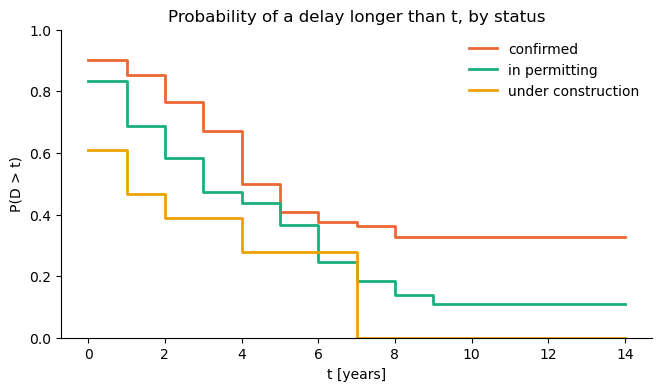

In [45]:
colours = {"confirmed": "#eb6834", "in_permitting": "#1baf7a", "under_construction": "#eda100"}
fig, ax = plt.subplots(figsize=(6.5, 3.8), layout="constrained")
for s, p in PMF.items():
    ax.step(survival.index, survival[s], where="post", color=colours[s], lw=2, label=s.replace("_", " "))
ax.set(xlabel="t [years]", ylabel="P(D > t)", ylim=(0, 1), title="Probability of a delay longer than t, by status")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 2. Transmission projects and their capacity

Projects come from the processed output of `build_transmission_projects` (plans and statuses from `TP_CONFIG`,
duplicates resolved by the pipeline). Only branches with at least one end in Germany are kept.

Capacity in TWkm: DC links use `p_nom * length`, new AC lines `s_nom * length`. An upgrade adds only
`(s_nom - s_nom of the replaced branch) * length`; the replaced branch is the base-network line or an earlier
upgrade stage. A project can span several model branches; they share one `project_id`.

With `CLUSTERED` (default), lengths are those the model sees: the distance between the two cluster centres of
`SOURCE_RUN`'s clustered network, and 0 for a branch within one cluster (invisible to the model). Buses added by
projects that the run's busmap does not know go to the nearest known bus. Scenario and simulated capacities use
the same lengths.

In [46]:
repo = Path.cwd().parent
tp = yaml.safe_load(TP_CONFIG)["transmission_projects"]
prefix = "tp-" + hashlib.sha1(json.dumps(tp).encode()).hexdigest()[:8]
run_dir = repo / "resources" / prefix / SCENARIO
proj_dir = run_dir / "transmission_projects"

if not (proj_dir / "new_lines.csv").exists():
    source = repo / "resources" / SOURCE_RUN / SCENARIO
    for fn in ["networks/base.nc", "offshore_shapes.geojson", "europe_shape.geojson"]:
        (run_dir / fn).parent.mkdir(parents=True, exist_ok=True)
        (run_dir / fn).unlink(missing_ok=True)
        (run_dir / fn).symlink_to(source / fn)
    override = run_dir / "transmission_projects_config.yaml"
    override.write_text(
        yaml.safe_dump({"run": {"prefix": prefix, "name": [SCENARIO]}, "transmission_projects": tp}, sort_keys=False)
    )
    target = (proj_dir / "new_lines.csv").relative_to(repo)
    subprocess.run(
        [sys.executable, "-m", "snakemake", str(target), "--configfile", str(override), "-c1",
         "--allowed-rules", "build_transmission_projects", "--rerun-triggers", "mtime"],
        cwd=repo,
        check=True,
    )

print(f"transmission projects from {proj_dir.relative_to(repo)}")

transmission projects from resources/tp-7a8d3334/KN2045_Bal_v5_abroad_capa_freeze/transmission_projects


In [47]:
n = pypsa.Network(run_dir / "networks" / "base.nc")
lines = pd.read_csv(proj_dir / "new_lines.csv", index_col=0)
links = pd.read_csv(proj_dir / "new_links.csv", index_col=0)
new_buses = pd.read_csv(proj_dir / "new_buses.csv", index_col=0)

# the pipeline writes column-less files when no buses are added or upgrades are skipped
country = n.buses.country
xy = n.buses[["x", "y"]]
if not new_buses.empty:
    country = pd.concat([country, new_buses.country])
    xy = pd.concat([xy, new_buses[["x", "y"]]])
if "replaced_asset" not in lines:
    lines["replaced_asset"] = np.nan


def touches_de(branches):
    return country.loc[branches.bus0].eq("DE").to_numpy() | country.loc[branches.bus1].eq("DE").to_numpy()


if CLUSTERED:
    source_dir = repo / "resources" / SOURCE_RUN / SCENARIO
    busmap = pd.read_csv(source_dir / "busmap_base_s.csv", index_col=0).iloc[:, 0]
    busmap = busmap.map(pd.read_csv(source_dir / f"busmap_base_s_{CLUSTERS}.csv", index_col=0).iloc[:, 0])
    centre = pypsa.Network(source_dir / "networks" / f"base_s_{CLUSTERS}.nc").buses[["x", "y"]]
    cluster = busmap.reindex(xy.index)
    missing = cluster.isna()
    nearest = ((xy[missing].to_numpy()[:, None] - xy[~missing].to_numpy()[None]) ** 2).sum(-1).argmin(1)
    cluster[missing] = cluster[~missing].iloc[nearest].to_numpy()
    print(f"clustered as {SOURCE_RUN} ({CLUSTERS}): {missing.sum()} buses not in its busmap, mapped to the nearest bus")


def branch_length(branches: pd.DataFrame) -> pd.Series:
    """Length in km: between cluster centres (0 within one cluster) if ``CLUSTERED``, else as built."""
    if not CLUSTERED:
        return branches["length"]
    c0, c1 = cluster.loc[branches.bus0].to_numpy(), cluster.loc[branches.bus1].to_numpy()
    d = haversine_pts(centre.loc[c0].to_numpy(), centre.loc[c1].to_numpy())
    return pd.Series(np.where(c0 == c1, 0.0, d), branches.index)


upgrade = lines.replaced_asset.notna()
s_nom = pd.concat([n.lines.s_nom, lines.s_nom])
s_nom_old = pd.Series(0.0, index=lines.index)
s_nom_old[upgrade] = s_nom.loc[lines.replaced_asset[upgrade]].to_numpy()
added = lines.s_nom - s_nom_old
print(f"{(added < 0).sum()} upgrades lower s_nom, counted as 0")

lines_cap = pd.DataFrame(
    {
        "project_id": lines["project_id"],
        "status": lines["project_status"],
        "build_year": lines["build_year"].astype(int),
        "twkm": added.clip(lower=0) * branch_length(lines) / 1e6,
        "kind": np.where(upgrade, "AC upgrade", "AC"),
    }
)[touches_de(lines)]
links_cap = pd.DataFrame(
    {
        "project_id": links["project_id"],
        "status": links["project_status"],
        "build_year": links["build_year"].astype(int),
        "twkm": links["p_nom"] * branch_length(links) / 1e6,
        "kind": "DC",
    }
)[touches_de(links)]

projects = pd.concat([links_cap, lines_cap])
projects.index.name = "branch"

print(f"{projects.project_id.nunique()} projects on {len(projects)} branches, {projects.twkm.sum():.1f} TWkm total, "
      f"{(projects.twkm == 0).sum()} branches without capacity")
projects.groupby(["kind", "build_year"]).twkm.agg(["count", "sum"]).round(2)

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.4)
INFO:pypsa.network.io:Imported network 'PyPSA-Eur (osm vlatest)' has buses, carriers, lines, links, shapes, transformers
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.4)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, lines, links, sub_networks


clustered as 20261027-NUTS2-365h-2025EXO-2030EXO-2035EXO-10-50-40-new-plots (adm): 3 buses not in its busmap, mapped to the nearest bus
19 upgrades lower s_nom, counted as 0
203 projects on 287 branches, 39.4 TWkm total, 190 branches without capacity


count   sum
kind       build_year             
AC         2026            2  2.01
           2027            5  0.81
           2029            4  0.00
           2030            1  0.00
           2031            2  0.39
           2032            5  1.83
           2033            2  0.65
           2034            2  0.17
           2035            3  0.67
           2037           17  5.51
           2038            1  0.00
           2045            3  1.70
AC upgrade 0               1  0.00
           2026           17  0.54
           2027           11  0.12
           2028           11  1.24
           2029           11  1.09
           2030           22  0.93
           2031           32  1.23
           2032           14  0.74
           2033           22  0.71
           2034            4  0.22
           2035           25  1.38
           2036            4  0.59
           2037           39  3.11
           2038            3  0.35
           2045            6  0.72
DC         2026            1  0.62
           2027            2  1.12
           2028            3  3.10
           2032            3  1.91
           2033            2  1.30
           2034            1  0.43
           2035            1  0.65
           2037            2  1.52
           2038            1  0.16
           2040            1  0.98
           2045            1  0.88

In [48]:
baseline = projects[projects.build_year <= BASE_YEAR]
stochastic = projects[projects.build_year > BASE_YEAR].copy()  # after 2035 too: early completion is possible
cap_base = baseline.twkm.sum()

print(f"baseline (planned <= {BASE_YEAR}): {baseline.project_id.nunique():3d} projects, {cap_base:6.1f} TWkm")
for label, part in stochastic.groupby(stochastic.build_year > HORIZON):
    span = f"after {HORIZON}" if label else f"{BASE_YEAR + 1}-{HORIZON}"
    print(f"stochastic {span}: {part.project_id.nunique():3d} projects, {part.twkm.sum():6.1f} TWkm")
pd.crosstab(stochastic.drop_duplicates("project_id").status, stochastic.drop_duplicates("project_id").kind)

baseline (planned <= 2025):   1 projects,    0.0 TWkm
stochastic 2026-2035: 141 projects,   23.9 TWkm
stochastic after 2035:  61 projects,   15.5 TWkm


kind,AC,AC upgrade,DC
status,,,
confirmed,33,81,3
in_permitting,13,43,9
under_construction,1,13,6


## 3. Scenario capacities

The "year-$y$ grid" contains all projects planned for completion up to $y$.

In [49]:
scenario_cap = pd.Series(
    {year: projects.loc[projects.build_year <= year, "twkm"].sum() for year in SCENARIO_YEARS},
    name="Cap [TWkm]",
)
scenario_cap.index.name = "grid year"
scenario_cap.round(2).to_frame()

,Cap [TWkm]
grid year,
2025,0.00
2026,3.17
2027,5.22
2028,9.56
2029,10.65
2030,11.58
2031,13.20
2032,17.68
2033,20.34


In [50]:
caps = scenario_cap.to_numpy()
# bin edges halfway between neighbouring scenario capacities, outer edges open
edges = np.concatenate([[-np.inf], (caps[:-1] + caps[1:]) / 2, [np.inf]])

pd.DataFrame(
    {"lower": edges[:-1], "Cap": caps, "upper": edges[1:]}, index=scenario_cap.index
).round(2)

,lower,Cap,upper
grid year,,,
2025,-inf,0.00,1.58
2026,1.58,3.17,4.19
2027,4.19,5.22,7.39
2028,7.39,9.56,10.10
2029,10.10,10.65,11.11
2030,11.11,11.58,12.39
2031,12.39,13.20,15.44
2032,15.44,17.68,19.01
2033,19.01,20.34,20.75


## 4. Monte Carlo

One experiment: draw a delay for every stochastic project from the distribution of its status, linked by the
one-factor copula; add it to the planned year; keep the projects that finish by 2035 and are not cancelled; sum
their capacity; assign the sum to a scenario bin. All branches of one project share its delay and cancellation.
Cancellation is independent of delay and of other projects. With `PMF_UNCERTAINTY`, each draw first picks one
bootstrap estimate of the delay distributions and all projects of that draw use it: the estimation error is
shared, so it acts like an extra common factor.

In [51]:
project_status = stochastic.groupby("project_id").status.agg(["first", "nunique"])
assert (project_status["nunique"] == 1).all(), "branches of one project differ in status"
project_status = project_status["first"]
assert project_status.isin(PMF).all(), f"no delay distribution for {set(project_status) - set(PMF)}"
project = project_status.index.get_indexer(stochastic.project_id)  # branch -> project
ids = project_status.index.to_series()
group, _ = pd.factorize(ids.str.split("_").str[1].where(ids.str.startswith("NEP_"), ids))  # NEP project, else own
build_year = stochastic.build_year.to_numpy()
twkm = stochastic.twkm.to_numpy()
cancel_p = project_status.map(CANCEL).to_numpy()


def quantile(p: pd.Series, u: np.ndarray) -> np.ndarray:
    """Delay at probability level u of a distribution given as probability per delay."""
    c = p.cumsum().to_numpy()
    return p.index.to_numpy()[np.minimum(np.searchsorted(c, u), c.size - 1)]


def simulate(
    rho: float, rho_project: float | None = None, seed: int = SEED, uncertain: bool = PMF_UNCERTAINTY
) -> tuple[pd.Series, np.ndarray]:
    """Scenario weights and realized capacities for one correlation setting.

    ``rho_project`` (sensitivity only) is the correlation of measures of one NEP project; ``None`` means ``rho``.
    ``uncertain`` draws one bootstrap estimate of the delay distributions per draw.
    """
    rho_project = rho if rho_project is None else rho_project
    rng = np.random.default_rng(seed)
    shape = (N_DRAWS, project_status.size)
    z = (np.sqrt(rho) * rng.standard_normal((N_DRAWS, 1))
         + np.sqrt(rho_project - rho) * rng.standard_normal((N_DRAWS, group.max() + 1))[:, group]
         + np.sqrt(1 - rho_project) * rng.standard_normal(shape))
    u = norm.cdf(z)
    delays = np.empty(shape)
    rep = rng.integers(N_REP, size=N_DRAWS) if uncertain else np.zeros(N_DRAWS, int)
    for s, p in PMF.items():
        m = (project_status == s).to_numpy()
        for k, q in enumerate(PMF_BOOT[s] if uncertain else [p]):
            r = rep == k
            delays[np.ix_(r, m)] = quantile(q, u[np.ix_(r, m)])
    cancelled = rng.random(shape) < cancel_p
    available = ((build_year + delays[:, project]) <= HORIZON) & ~cancelled[:, project]
    cap = cap_base + available @ twkm
    counts = np.bincount(np.digitize(cap, edges[1:-1]), minlength=len(SCENARIO_YEARS))
    return pd.Series(counts / N_DRAWS, index=scenario_cap.index, name="probability"), cap


weights, realized_cap = simulate(rho)
result = pd.concat([scenario_cap.round(2), weights.round(4)], axis=1)
result["delay [a]"] = HORIZON - result.index
print(f"sum of weights: {weights.sum():.4f}")
result

sum of weights: 1.0000


,Cap [TWkm],probability,delay [a]
grid year,,,
2025,0.00,0.0001,10
2026,3.17,0.0040,9
2027,5.22,0.0241,8
2028,9.56,0.0803,7
2029,10.65,0.0682,6
2030,11.58,0.1267,5
2031,13.20,0.3737,4
2032,17.68,0.2641,3
2033,20.34,0.0401,2


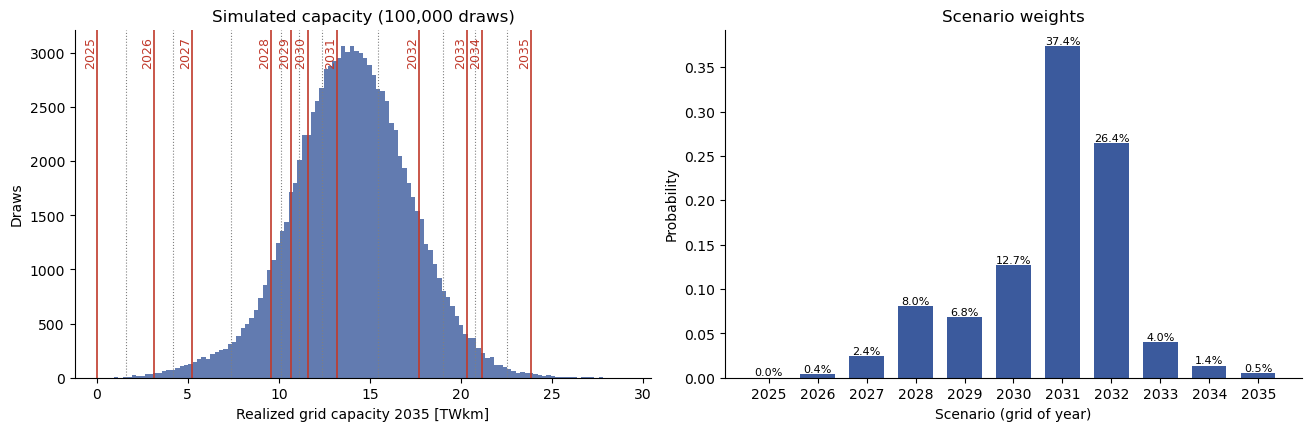

In [52]:
fig, axs = plt.subplot_mosaic([["cap", "weights"]], figsize=(13, 4.2), layout="constrained")
ax = axs["cap"]
ax.hist(realized_cap, bins=120, color="#3b5a9d", alpha=0.8)
for year, cap in scenario_cap.items():
    ax.axvline(cap, color="#c0392b", lw=1.2)
    ax.text(cap, 0.98, str(year), rotation=90, ha="right", va="top", color="#c0392b", fontsize=9,
            transform=ax.get_xaxis_transform())
for edge in edges[1:-1]:
    ax.axvline(edge, color="grey", lw=0.8, ls=":")
ax.set(xlabel="Realized grid capacity 2035 [TWkm]", ylabel="Draws", title=f"Simulated capacity ({N_DRAWS:,} draws)")

ax = axs["weights"]
x = np.arange(len(SCENARIO_YEARS))
ax.bar(x, weights.to_numpy(), color="#3b5a9d", width=0.7)
for i, value in enumerate(weights.to_numpy()):
    ax.text(i, value, f"{value:.1%}", ha="center", va="bottom", fontsize=8)
ax.set(xticks=x, xticklabels=SCENARIO_YEARS, xlabel="Scenario (grid of year)", ylabel="Probability",
       title="Scenario weights")
for ax in axs.values():
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 5. Exact cross-check

With independent projects, the capacity distribution can be convolved exactly, project by project over all its
delays. Monte Carlo with both correlations set to 0 must agree up to sampling noise (about +-0.002).

In [53]:
resolution = 1e-3  # TWkm grid
grid_cap = np.rint(twkm / resolution).astype(int)

pmf_cap = np.zeros(grid_cap.sum() + 1)
pmf_cap[0] = 1.0
for i, s in enumerate(project_status):
    in_project = project == i
    convolved = cancel_p[i] * pmf_cap
    for delay, prob in PMF[s].items():
        step = grid_cap[in_project & (build_year + delay <= HORIZON)].sum()
        convolved[step:] += (1 - cancel_p[i]) * prob * pmf_cap[: pmf_cap.size - step]
    pmf_cap = convolved

support = cap_base + np.arange(pmf_cap.size) * resolution
exact = pd.Series(np.bincount(np.digitize(support, edges[1:-1]), weights=pmf_cap, minlength=len(SCENARIO_YEARS)),
                  index=scenario_cap.index)
independent, _ = simulate(0.0, uncertain=False)
check = pd.concat({"monte carlo, independent": independent, "exact, independent": exact}, axis=1)
assert (check.diff(axis=1).iloc[:, 1].abs() < 0.01).all(), "Monte Carlo and exact convolution disagree"
check.round(4).T

grid year,2025,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035
"monte carlo, independent",0.0,0.0,0.0,0.0001,0.0030,0.0423,0.6676,0.2858,0.0012,0.0,0.0
"exact, independent",0.0,0.0,0.0,0.0001,0.0028,0.0427,0.6677,0.2853,0.0014,0.0,0.0


## 6. Sensitivity

Weights for the correlation estimate and its 90 % interval, fully independent, with an extra project level
(`RHO_PROJECT`, not used in the main run), and with uncertain delay distributions (`PMF_UNCERTAINTY`).
In the figure, vertical lines span the weights over the 90 % interval of the correlation.

In [54]:
RHO_PROJECT = 0.53  # same NEP project, nep_panel_delay_explorer.ipynb Table 7; not exported
runs = {
    "independent": dict(rho=0.0),
    f"rho {RHO.lo['period']:.2f} (90 % low)": dict(rho=RHO.lo["period"]),
    f"project {RHO_PROJECT:.2f} only": dict(rho=0.0, rho_project=RHO_PROJECT),
    f"rho {rho:.2f}, project {RHO_PROJECT:.2f}": dict(rho=rho, rho_project=RHO_PROJECT),
    f"rho {rho:.2f}, uncertain delay distribution": dict(rho=rho, uncertain=True),
    f"rho {rho:.2f} (main)": dict(rho=rho),
    f"rho {RHO.hi['period']:.2f} (90 % high)": dict(rho=RHO.hi["period"]),
}
sens = pd.DataFrame({name: simulate(**r)[0] for name, r in runs.items()})
mean_slip = (sens.mul(HORIZON - sens.index, axis=0)).sum().rename("expected programme slip [a]")
pd.concat([sens.T.round(3), mean_slip.round(2)], axis=1)

,2025,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035,expected programme slip [a]
independent,0.000,0.000,0.002,0.032,0.040,0.109,0.604,0.211,0.002,0.000,0.000,4.08
rho 0.02 (90 % low),0.000,0.000,0.005,0.040,0.046,0.117,0.551,0.235,0.006,0.000,0.000,4.10
project 0.53 only,0.000,0.000,0.003,0.033,0.040,0.113,0.592,0.218,0.002,0.000,0.000,4.08
"rho 0.17, project 0.53",0.000,0.004,0.025,0.078,0.070,0.125,0.374,0.263,0.040,0.014,0.005,4.22
"rho 0.17, uncertain delay distribution",0.000,0.004,0.024,0.080,0.068,0.127,0.374,0.264,0.040,0.014,0.005,4.22
rho 0.17 (main),0.000,0.004,0.024,0.080,0.068,0.127,0.374,0.264,0.040,0.014,0.005,4.22
rho 0.27 (90 % high),0.001,0.009,0.032,0.101,0.074,0.119,0.319,0.255,0.053,0.024,0.014,4.26


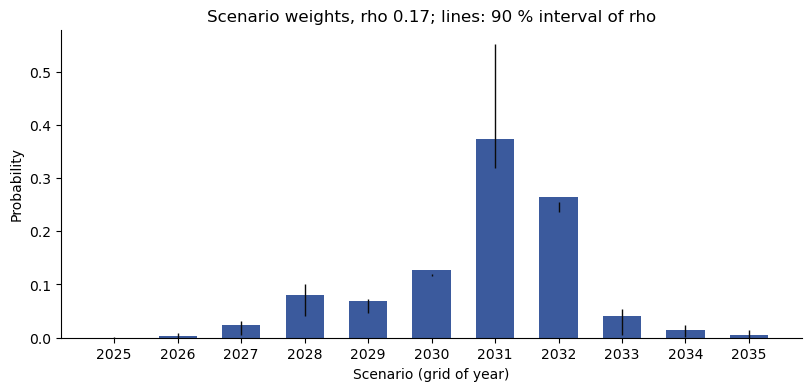

In [55]:
fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
x = np.arange(len(SCENARIO_YEARS))
main = f"rho {rho:.2f} (main)"
ax.bar(x, sens[main], width=0.6, color="#3b5a9d")
lo_name, hi_name = list(runs)[1], list(runs)[-1]
ax.vlines(x, sens[[lo_name, hi_name]].min(axis=1), sens[[lo_name, hi_name]].max(axis=1), color="#0b0b0b", lw=1)
ax.set(xticks=x, xticklabels=SCENARIO_YEARS, xlabel="Scenario (grid of year)", ylabel="Probability",
       title=f"Scenario weights, rho {rho:.2f}; lines: 90 % interval of rho")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Reading the sensitivity:

- **The period correlation drives the spread.** It widens the capacity distribution from a standard deviation of
  about 1.4 TWkm (independent) to 2.8 TWkm and moves weight from 2031 into the tails (2028-2030, 2033-2035).
- **Why there is no project level.** Measures of one NEP project slip together (rho ~ 0.53, explorer Table 7), but
  adding that factor changes the weights only by Monte Carlo noise (total variation about 0.003; two seeds differ
  by 0.004). Alone, it widens the spread only from 1.39 to 1.44 TWkm. The variance of the sum counts pairs of
  projects, weighted by capacity; only 0.6 % of these pairs lie within one NEP project (groups of 2-4 measures),
  while the period factor links all of them. The simpler one-factor model is kept.
- **Uncertain delay distribution (`PMF_UNCERTAINTY`)** widens the capacity distribution (standard deviation 2.8 ->
  3.3 TWkm) but not on both sides. The variance of a mixture is E[Var | estimate] + Var(E | estimate); the second
  term is never negative, the first need not exceed the point estimate's variance. Here both grow, but the mean also
  drops (14.7 -> 14.0 TWkm): the bootstrap estimates are on average more delayed than the point estimate. Weight
  moves to the low grids (2027-2030), the high ones (2032-2035) lose slightly. Off by default.
- **Clustering (`CLUSTERED`)**: in the clustered network, about 180 of 287 branches lie within one cluster and count 0
  (mostly AC upgrades); branches between clusters get the distance between cluster centres (median 1.9 x their
  length). Total capacity changes little (40.4 -> 39.4 TWkm) and the relative spread not at all (standard deviation
  / mean 0.19 in both). With unclustered lengths the weights shift by at most 0.03 towards the middle grids
  (2028: 0.036 -> 0.019, 2031: 0.411 -> 0.444); the numbers above use the clustered network.


In [56]:
result.to_csv("grid_delay_scenario_weights_nep_panel.csv")
result

,Cap [TWkm],probability,delay [a]
grid year,,,
2025,0.00,0.0001,10
2026,3.17,0.0040,9
2027,5.22,0.0241,8
2028,9.56,0.0803,7
2029,10.65,0.0682,6
2030,11.58,0.1267,5
2031,13.20,0.3737,4
2032,17.68,0.2641,3
2033,20.34,0.0401,2


## Assumptions

- **Status at NEP 2023.** A project's delay distribution is the one of its NEP 2023 status. Later reports (NEP
  2025) know more about some projects; they are not used here.
- **Delay is measured against one report's target**, for reports at least 3 years before the target. Pooled over
  2012-2025; a stable delay process is assumed. TYNDP 2022 projects (cross-border) use the same distributions.
- **Censoring-aware, not optimistic.** Lines still open count with what is known (not done by March 2026). Mass the
  data cannot place counts as "not by 2035".
- **Correlation from target slips.** rho is the intra-class correlation of normal scores of target slips per NEP
  period (8 periods, wide interval); part of it may be reporting practice. No extra factor for measures of one NEP
  project: it does not change the weights (section 6).
- **Cancellation** is the NEP life-table probability per status, independent of delay and of other projects. 0 for
  construction rests on 67 lines that left that phase.
- **Capacity as the model sees it** (`CLUSTERED`): branches within one cluster count 0, the others the distance
  between cluster centres. Unclustered lengths give a similar relative spread (section 6).
- Delay does not depend on project size or technology (DC samples are too small); capacity matching as before.